# Cómo se simula la señal del teléfono

Este notebook explica, paso a paso, cómo el simulador [`vehicle-bridge-signal-generator`](../../sensing-techniques/tools/vehicle-bridge-signal-generator/) genera la aceleración que mide un teléfono dentro de un carro que cruza un puente.

- Se reproduce un viaje con los parámetros del **viaje 6** del paquete `p02-five-bridges-traffic` (puente B3, 14 m/s).
- El código es una versión simplificada del simulador: sigue los mismos pasos y fórmulas, pero usa sus propios números aleatorios, así que las curvas no son idénticas a las del archivo.

## Índice

1. Parámetros del ejemplo
2. Vibración del puente
3. Rugosidad de la carretera
4. Lo que pisa la rueda
5. El carro
6. Separar la señal por fuentes
7. El teléfono
8. Resumen

La Figura 1 muestra el camino completo: cada caja es una sección del notebook.

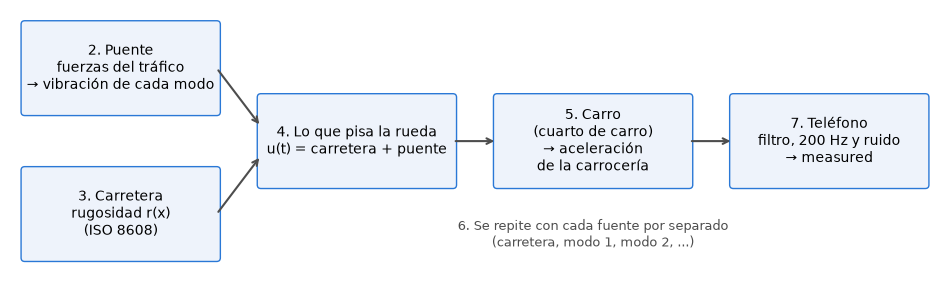

In [1]:
# Diagram only
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 3.6))
boxes = {
    "bridge": (0.0, 2.0, "2. Puente\nfuerzas del tráfico\n→ vibración de cada modo"),
    "road": (0.0, 0.0, "3. Carretera\nrugosidad r(x)\n(ISO 8608)"),
    "wheel": (3.2, 1.0, "4. Lo que pisa la rueda\nu(t) = carretera + puente"),
    "car": (6.4, 1.0, "5. Carro\n(cuarto de carro)\n→ aceleración\nde la carrocería"),
    "phone": (9.6, 1.0, "7. Teléfono\nfiltro, 200 Hz y ruido\n→ measured"),
}
for x0, y0, text in boxes.values():
    ax.add_patch(FancyBboxPatch((x0, y0), 2.6, 1.2, boxstyle="round,pad=0.05", fc="#eef3fb", ec="#2a78d6"))
    ax.text(x0 + 1.3, y0 + 0.6, text, ha="center", va="center", fontsize=10)
arrow = dict(arrowstyle="->", lw=1.5, color="0.3")
ax.annotate("", (3.2, 1.8), (2.6, 2.6), arrowprops=arrow)
ax.annotate("", (3.2, 1.4), (2.6, 0.6), arrowprops=arrow)
ax.annotate("", (6.4, 1.6), (5.8, 1.6), arrowprops=arrow)
ax.annotate("", (9.6, 1.6), (9.0, 1.6), arrowprops=arrow)
ax.text(7.7, 0.55, "6. Se repite con cada fuente por separado\n(carretera, modo 1, modo 2, ...)",
        ha="center", va="top", fontsize=9, color="0.3")
ax.set_xlim(-0.2, 12.4)
ax.set_ylim(-0.4, 3.4)
ax.axis("off")
plt.show()

**Figura 1.** Camino de la simulación. El puente y la carretera se generan por separado; la rueda pisa la suma de los dos; el carro filtra esa entrada; el teléfono registra la aceleración de la carrocería, con su filtro y su ruido.

## 1. Parámetros del ejemplo

**Tabla 1.** Parámetros del ejemplo (los del viaje 6 de `p02`, redondeados).

| Parte | Parámetro | Valor |
|---|---|---|
| Puente | luz L | 35 m |
| | frecuencia del modo 1, f1 | 3.0 Hz |
| | amortiguamiento ζ (todos los modos) | 1.2 % |
| | aceleración modal RMS (tráfico) | 0.065 m/s² |
| Carretera | clase ISO 8608 | C (G_d(n0) = 357·10⁻⁶ m³) |
| Carro | velocidad v | 14 m/s |
| | masa de la carrocería m_s / de la rueda m_u | 380 kg / 37 kg |
| | frecuencia de rebote / de salto de rueda | 1.79 Hz / 13.8 Hz |
| | amortiguamiento de la suspensión ζ_s | 21 % |
| Teléfono | ruido blanco | 312 µg/√Hz |

La simulación avanza en pasos de 0.001 s (1000 muestras por segundo). El teléfono guarda 200 muestras por segundo.

Antes del viaje se simulan 10 s de **calentamiento**, que luego se descartan. Así el puente ya está vibrando y el carro ya está estable cuando empieza la ventana que se guarda.

In [2]:
import numpy as np
from scipy import signal

SEED = 42
rng = np.random.default_rng(SEED)

# Bridge (B3)
L = 35.0              # span [m]
f1 = 3.0              # first natural frequency [Hz]
zeta_bridge = 0.012   # damping ratio of every mode
n_modes = 3           # modes with f_n <= 40 Hz: 3, 12 and 27 Hz
accel_rms = 0.065     # modal acceleration RMS, bridge excited by traffic [m/s^2]

# Road
gd_n0 = 357e-6        # roughness level G_d(n0), class C [m^3]

# Car (quarter car)
v = 14.0              # speed [m/s]
m_s, m_u = 380.0, 37.0        # body and wheel mass [kg]
f_body, f_wheel = 1.79, 13.8  # body bounce and wheel hop frequencies [Hz]
zeta_s = 0.21                 # suspension damping ratio

# Phone
noise_density = 312.0  # white noise [micro-g / sqrt(Hz)]

# Time and position
FS_SIM = 1000          # simulation samples per second
FS_OUT = 200           # phone samples per second
dt = 1 / FS_SIM
road_before = road_after = 100.0   # road before and after the bridge [m]
t_warm = 10.0                      # warm-up, discarded [s]

duration = (road_before + L + road_after) / v
t = np.arange(-t_warm, duration, dt)     # time [s] (0 = start of the saved window)
x = -road_before + v * t                 # wheel position [m] (0 = start of the bridge)
on_bridge = (x >= 0) & (x <= L)
keep = t >= 0                            # samples of the saved window
print(f"Window: {duration:.1f} s, the car is on the bridge from {t[on_bridge][0]:.2f} to {t[on_bridge][-1]:.2f} s")

Window: 16.8 s, the car is on the bridge from 7.14 to 9.64 s


## 2. Vibración del puente

El puente es una viga simplemente apoyada. Su movimiento vertical es la suma del movimiento de cada modo:

$$w(x,t) = \sum_{n=1}^{N} \phi_n(x)\, q_n(t) \tag{1}$$

$$\phi_n(x) = \sin\!\left(\frac{n \pi x}{L}\right), \qquad f_n = n^2 f_1 \tag{2}$$

- $w(x,t)$: desplazamiento vertical del puente en la posición $x$ y el instante $t$ [m].
- $\phi_n(x)$: forma del modo $n$ (vale 0 en los apoyos).
- $q_n(t)$: cuánto se mueve el modo $n$ en el tiempo [m].
- $f_n$: frecuencia del modo $n$; $N$: número de modos con $f_n \le 40$ Hz (aquí 3).

Cada modo se comporta como una masa con un resorte y un amortiguador, empujada por una fuerza:

$$\ddot q_n + 2 \zeta \omega_n \dot q_n + \omega_n^2 q_n = p_n(t) \tag{3}$$

- $\omega_n = 2\pi f_n$: frecuencia angular [rad/s]; $\zeta$: amortiguamiento.
- $\dot q_n$, $\ddot q_n$: velocidad y aceleración del modo.
- $p_n(t)$: fuerza aleatoria (ruido blanco) que representa el **tráfico**: empujones al azar, en todas las frecuencias.

Después se escala cada modo para que su amplitud sea $\mathrm{RMS}(q_n) = a_\mathrm{RMS} / \omega_n^2$, con $a_\mathrm{RMS}$ = 0.065 m/s². Así todos los modos tienen la misma aceleración RMS en su propia frecuencia.

**Cómo se resuelve:** con el método de **Newmark** (aceleración promedio). El tiempo se divide en pasos de 0.001 s. En cada paso se calcula la posición nueva, suponiendo que la aceleración durante el paso es el promedio de la del inicio y la del final. La misma función sirve para el puente (sección 2) y para el carro (sección 5). Resuelve ecuaciones de la forma $\mathbf{M}\ddot{\mathbf{y}} + \mathbf{C}\dot{\mathbf{y}} + \mathbf{K}\mathbf{y} = \mathbf{F}(t)$, con $\mathbf{M}$ masas, $\mathbf{C}$ amortiguamientos, $\mathbf{K}$ rigideces y $\mathbf{F}$ fuerzas.

In [3]:
def newmark(M, C, K, F, dt, y0=None):
    """Solve M y'' + C y' + K y = F(t) step by step (Newmark, average acceleration).
    F has one row per time step and one column per degree of freedom."""
    M, C, K = np.atleast_2d(M), np.atleast_2d(C), np.atleast_2d(K)
    n_steps, n_dof = F.shape
    y, yd, ydd = np.zeros((n_steps, n_dof)), np.zeros((n_steps, n_dof)), np.zeros((n_steps, n_dof))
    if y0 is not None:
        y[0] = y0
    ydd[0] = np.linalg.solve(M, F[0] - C @ yd[0] - K @ y[0])
    K_eff_inv = np.linalg.inv(K + 2 / dt * C + 4 / dt**2 * M)
    for k in range(n_steps - 1):
        rhs = F[k + 1] + M @ (4 / dt**2 * y[k] + 4 / dt * yd[k] + ydd[k]) + C @ (2 / dt * y[k] + yd[k])
        y[k + 1] = K_eff_inv @ rhs
        yd[k + 1] = 2 / dt * (y[k + 1] - y[k]) - yd[k]
        ydd[k + 1] = 4 / dt**2 * (y[k + 1] - y[k]) - 4 / dt * yd[k] - ydd[k]
    return y, yd, ydd


# Modes of the bridge (Eq. 2) and their equations (Eq. 3), all solved together
f_modes = np.array([n**2 * f1 for n in range(1, n_modes + 1)])
w_modes = 2 * np.pi * f_modes
M_bridge = np.eye(n_modes)
C_bridge = np.diag(2 * zeta_bridge * w_modes)
K_bridge = np.diag(w_modes**2)
p = rng.standard_normal((len(t), n_modes))    # white noise force: the traffic

q, qd, qdd = newmark(M_bridge, C_bridge, K_bridge, p, dt)

# Scale every mode so that RMS(q_n) = accel_rms / w_n^2
scale = (accel_rms / w_modes**2) / q[keep].std(axis=0)
q, qdd = q * scale, qdd * scale
for n in range(n_modes):
    print(f"Mode {n + 1}: f = {f_modes[n]:4.1f} Hz, RMS of q = {q[keep, n].std() * 1000:.4f} mm")

Mode 1: f =  3.0 Hz, RMS of q = 0.1829 mm
Mode 2: f = 12.0 Hz, RMS of q = 0.0114 mm
Mode 3: f = 27.0 Hz, RMS of q = 0.0023 mm


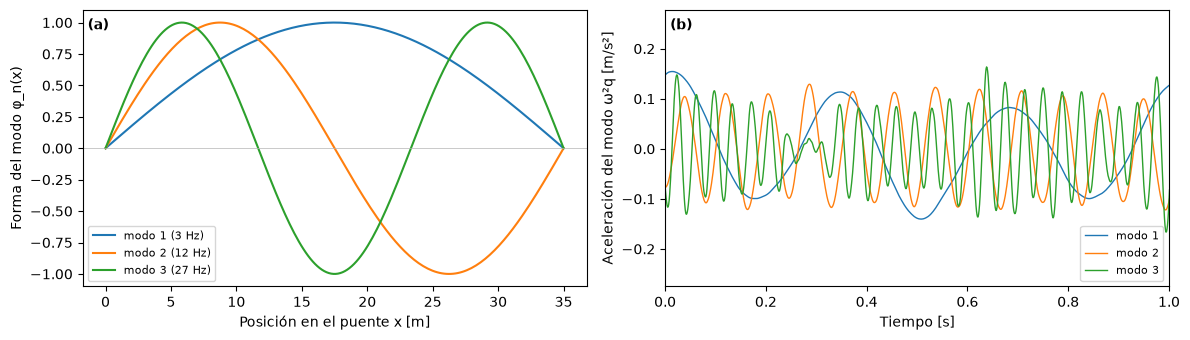

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
x_beam = np.linspace(0, L, 200)
for n in range(n_modes):
    ax1.plot(x_beam, np.sin((n + 1) * np.pi * x_beam / L), label=f"modo {n + 1} ({f_modes[n]:.0f} Hz)")
    ax2.plot(t, w_modes[n]**2 * q[:, n], lw=1, label=f"modo {n + 1}")
ax1.axhline(0, color="0.7", lw=0.5)
ax1.set_xlabel("Posición en el puente x [m]")
ax1.set_ylabel("Forma del modo φ_n(x)")
ax1.legend(loc="lower left", fontsize=8)
ax2.set_xlim(0, 1)
ax2.set_xlabel("Tiempo [s]")
ax2.set_ylabel("Aceleración del modo ω²q [m/s²]")
ax2.legend(loc="lower right", fontsize=8)
for ax, letter in zip((ax1, ax2), "ab"):
    ax.text(0.01, 0.97, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 2.** Modos del puente del ejemplo. (a) Forma de cada modo a lo largo del puente (Ec. 2). (b) Aceleración de cada modo durante 1 s ($\omega_n^2 q_n$).

- Los tres modos tienen una aceleración parecida, pero el modo 3 oscila 9 veces más rápido que el modo 1.
- En desplazamiento es al revés: el modo 1 domina, porque $q_n = $ aceleración $/\,\omega_n^2$.

## 3. Rugosidad de la carretera

La norma ISO 8608 describe la rugosidad con su **densidad espectral**: cuánta altura tiene el perfil en cada longitud de onda.

$$G_d(n) = G_d(n_0) \left(\frac{n}{n_0}\right)^{-2} \tag{4}$$

- $n$: frecuencia espacial [ciclos/m]; $1/n$ es la longitud de onda (aquí de 0.1 m a 100 m).
- $n_0 = 0.1$ ciclos/m: frecuencia de referencia.
- $G_d(n_0)$: nivel de rugosidad, que define la clase: A ≈ 16, B ≈ 64, C ≈ 256 (·10⁻⁶ m³).
- El exponente −2 dice que las ondas largas tienen mucha más altura que las cortas.

El perfil se arma sumando muchas ondas (cosenos), cada una con la altura que da la Ec. 4 y una fase al azar:

$$r(x) = \sum_i \sqrt{2\, G_d(n_i)\, \Delta n}\; \cos(2 \pi n_i x + \varphi_i) \tag{5}$$

- $r(x)$: altura de la carretera en la posición $x$ [m].
- $n_i$: frecuencias espaciadas cada $\Delta n$; $\varphi_i$: fase al azar entre 0 y $2\pi$.

La llanta no toca un punto sino una zona de unos 0.25 m. Por eso las ondas muy cortas se suavizan: cada amplitud se multiplica por $\mathrm{sinc}(0.25\, n_i)$.

In [5]:
n0 = 0.1
dn = 1 / 2048                         # spacing of the spatial frequencies [cycles/m]
n = np.arange(0.01, 10.0, dn)         # spatial frequencies [cycles/m]
Gd = gd_n0 * (n / n0) ** -2           # Eq. 4
amplitude = np.sqrt(2 * Gd * dn) * np.sinc(0.25 * n)   # Eq. 5, smoothed by the tyre contact
phase = rng.uniform(0, 2 * np.pi, len(n))

r = np.zeros(len(x))                  # road height under the wheel at every time step [m]
for a_i, n_i, ph_i in zip(amplitude, n, phase):
    r += a_i * np.cos(2 * np.pi * n_i * x + ph_i)
print(f"{len(n)} waves, RMS height of the road = {r[keep].std() * 1000:.1f} mm")

20460 waves, RMS height of the road = 24.3 mm


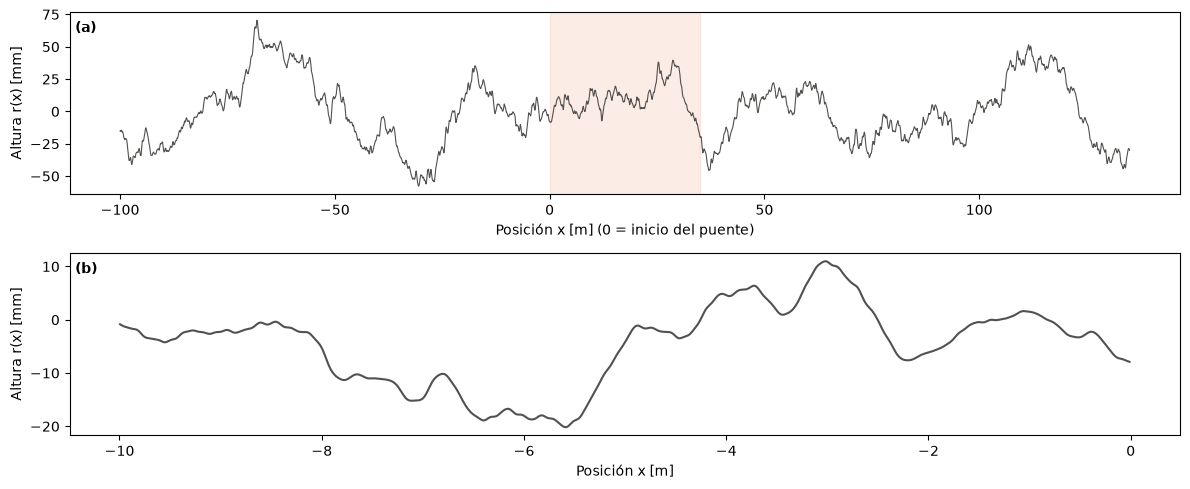

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5))
ax1.plot(x[keep], r[keep] * 1000, color="#52514e", lw=0.8)
ax1.axvspan(0, L, color="#eb6834", alpha=0.12)
ax1.set_xlabel("Posición x [m] (0 = inicio del puente)")
zoom = keep & (x >= -10) & (x <= 0)
ax2.plot(x[zoom], r[zoom] * 1000, color="#52514e")
ax2.set_xlabel("Posición x [m]")
for ax, letter in zip((ax1, ax2), "ab"):
    ax.set_ylabel("Altura r(x) [mm]")
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 3.** Perfil de la carretera del ejemplo (clase C). (a) Todo el recorrido; la franja naranja es el puente (el pavimento del tablero también es rugoso). (b) Zoom a los 10 m antes del puente: las ondas largas dan la forma general y las cortas, los detalles.

## 4. Lo que pisa la rueda

La rueda avanza a velocidad constante:

$$x(t) = x_0 + v\,t \tag{6}$$

En cada instante, la altura que pisa es la carretera más el movimiento del puente en ese punto (Ec. 1):

$$u(t) = r\big(x(t)\big) + \sum_{n=1}^{N} \phi_n\big(x(t)\big)\, q_n(t) \tag{7}$$

- $u(t)$: altura bajo la rueda [m]; es la **entrada del carro**.
- Fuera del puente $\phi_n = 0$, así que la rueda solo pisa la carretera.
- La interacción es **desacoplada**: el carro no empuja al puente. Por eso el puente se pudo simular antes y sin el carro (sección 2).

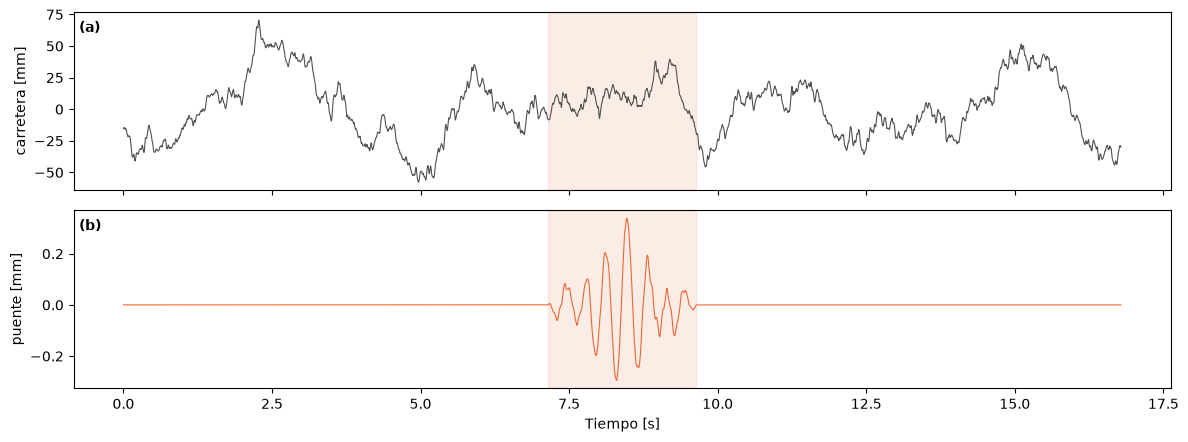

In [7]:
# Mode shapes under the wheel (zero outside the bridge)
phi = np.zeros((len(t), n_modes))
for k in range(n_modes):
    phi[on_bridge, k] = np.sin((k + 1) * np.pi * x[on_bridge] / L)

u_road = r                       # road part of the input [m]
u_modes = phi * q                # bridge part, one column per mode [m]
u = u_road + u_modes.sum(axis=1) # Eq. 7

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
ax1.plot(t[keep], u_road[keep] * 1000, color="#52514e", lw=0.8)
ax1.set_ylabel("carretera [mm]")
ax2.plot(t[keep], u_modes[keep].sum(axis=1) * 1000, color="#eb6834", lw=0.8)
ax2.set_ylabel("puente [mm]")
ax2.set_xlabel("Tiempo [s]")
for ax, letter in zip((ax1, ax2), "ab"):
    ax.axvspan(t[on_bridge][0], t[on_bridge][-1], color="#eb6834", alpha=0.12)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 4.** Las dos partes de lo que pisa la rueda. (a) Carretera, $r(x(t))$. (b) Movimiento del puente bajo la rueda, $\sum \phi_n q_n$. La franja naranja es el tiempo sobre el puente. Cada panel tiene su propia escala.

- El puente aparece solo mientras la rueda está encima, y su movimiento es unas **100 veces más pequeño** que la carretera.
- Al entrar y salir vale 0, porque las formas modales valen 0 en los apoyos.

## 5. El carro

El carro se modela como un **cuarto de carro**: una rueda y la parte de la carrocería que le corresponde (Figura 5).

- La **llanta** es un resorte $k_t$ entre el suelo y la rueda.
- La **suspensión** es un resorte $k_s$ y un amortiguador $c_s$ entre la rueda y la carrocería.
- El **teléfono** va en la carrocería y mide su aceleración $\ddot y_s$.

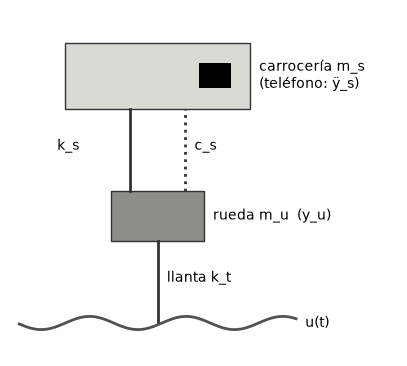

In [8]:
# Diagram only
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.add_patch(plt.Rectangle((0, 3.0), 2.0, 0.8, fc="#d9d9d6", ec="0.2"))   # body
ax.add_patch(plt.Rectangle((0.5, 1.4), 1.0, 0.6, fc="#8c8c88", ec="0.2")) # wheel
ax.add_patch(plt.Rectangle((1.45, 3.25), 0.35, 0.3, fc="black"))          # phone
ax.plot([0.7, 0.7], [2.0, 3.0], color="0.2", lw=2)                         # suspension spring
ax.plot([1.3, 1.3], [2.0, 3.0], color="0.2", lw=2, ls=":")                 # suspension damper
ax.plot([1.0, 1.0], [0.4, 1.4], color="0.2", lw=2)                         # tyre spring
x_road = np.linspace(-0.5, 2.5, 100)
ax.plot(x_road, 0.4 + 0.08 * np.sin(6 * x_road), color="#52514e", lw=2)    # road
ax.text(2.1, 3.4, "carrocería m_s\n(teléfono: ÿ_s)", va="center")
ax.text(1.6, 1.7, "rueda m_u  (y_u)", va="center")
ax.text(0.15, 2.5, "k_s", ha="right")
ax.text(1.4, 2.5, "c_s")
ax.text(1.1, 0.9, "llanta k_t")
ax.text(2.6, 0.4, "u(t)", va="center")
ax.set_xlim(-0.6, 3.6)
ax.set_ylim(0, 4.2)
ax.axis("off")
plt.show()

**Figura 5.** Esquema del cuarto de carro. La carretera mueve la base de la llanta ($u$); la rueda ($y_u$) y la carrocería ($y_s$) se mueven en respuesta; el teléfono mide la aceleración de la carrocería.

Las ecuaciones de movimiento (equilibrio de fuerzas en cada masa) son:

$$m_u \ddot y_u + c_s(\dot y_u - \dot y_s) + k_s(y_u - y_s) + k_t\,(y_u - u) = 0 \tag{8}$$

$$m_s \ddot y_s + c_s(\dot y_s - \dot y_u) + k_s(y_s - y_u) = 0 \tag{9}$$

- $y_u$, $y_s$: desplazamiento de la rueda y de la carrocería [m].
- La carretera entra solo por la llanta, como una fuerza $k_t\,u(t)$ sobre la rueda.

Las rigideces se calculan a partir de las dos frecuencias del carro (rebote $f_b$ y salto de rueda $f_w$):

$$\frac{k_s k_t}{k_s + k_t} = m_s (2\pi f_b)^2, \qquad k_s + k_t = m_u (2\pi f_w)^2 \tag{10}$$

y el amortiguamiento, con $c_s = 2 \zeta_s \sqrt{k_s m_s}$.

Se resuelve con la misma función `newmark` de la sección 2.

In [9]:
# Stiffnesses from the two frequencies (Eq. 10)
a = m_u * (2 * np.pi * f_wheel) ** 2
b = m_s * (2 * np.pi * f_body) ** 2
k_t = (a + np.sqrt(a * a - 4 * a * b)) / 2    # tyre
k_s = a - k_t                                 # suspension
c_s = 2 * zeta_s * np.sqrt(k_s * m_s)
print(f"k_s = {k_s / 1000:.1f} kN/m, k_t = {k_t / 1000:.1f} kN/m, c_s = {c_s:.0f} N s/m")

# Eq. 8 and 9 as matrices: degrees of freedom [y_u, y_s]
M_car = np.diag([m_u, m_s])
C_car = np.array([[c_s, -c_s], [-c_s, c_s]])
K_car = np.array([[k_t + k_s, -k_s], [-k_s, k_s]])


def body_acceleration(u_in):
    """Acceleration of the car body (where the phone is) for a road input u_in [m]."""
    F = np.zeros((len(u_in), 2))
    F[:, 0] = k_t * u_in                                   # the road pushes the wheel through the tyre
    y, yd, ydd = newmark(M_car, C_car, K_car, F, dt, y0=[u_in[0], u_in[0]])  # start at rest on the road
    return ydd[:, 1]


body_acc = body_acceleration(u)
print(f"RMS of the body acceleration: {body_acc[keep].std():.2f} m/s^2")

k_s = 61.8 kN/m, k_t = 216.4 kN/m, c_s = 2035 N s/m


RMS of the body acceleration: 1.84 m/s^2


## 6. Separar la señal por fuentes

El carro es **lineal**: si la entrada es una suma, la respuesta es la suma de las respuestas a cada parte. Escribiendo $\mathcal{H}\{\cdot\}$ para "la aceleración de la carrocería que produce esta entrada":

$$\ddot y_s = \mathcal{H}\{u\} = \mathcal{H}\{r\} + \sum_{n=1}^{N} \mathcal{H}\{\phi_n q_n\} \tag{11}$$

Por eso el simulador pasa cada parte de la entrada por el carro **por separado**: una vez solo la carretera y una vez cada modo del puente. Cada respuesta es un **componente** de la señal (`components/roughness`, `components/bridge_mode_1`, ...). Su suma da exactamente la respuesta total.

In [10]:
acc_road = body_acceleration(u_road)
acc_modes = np.column_stack([body_acceleration(u_modes[:, k]) for k in range(n_modes)])
acc_bridge = acc_modes.sum(axis=1)

difference = np.abs(body_acc - (acc_road + acc_bridge)).max()
print(f"Max |total - (road + bridge)| = {difference:.1e} m/s^2  (only round-off)")

# Share of each mode in the bridge part that reaches the body, on the bridge
energy = (acc_modes[on_bridge] ** 2).sum(axis=0)
for k in range(n_modes):
    print(f"Mode {k + 1}: {100 * energy[k] / energy.sum():.1f} % of the bridge part in the car")

Max |total - (road + bridge)| = 1.3e-10 m/s^2  (only round-off)
Mode 1: 98.3 % of the bridge part in the car
Mode 2: 1.7 % of the bridge part in the car
Mode 3: 0.0 % of the bridge part in the car


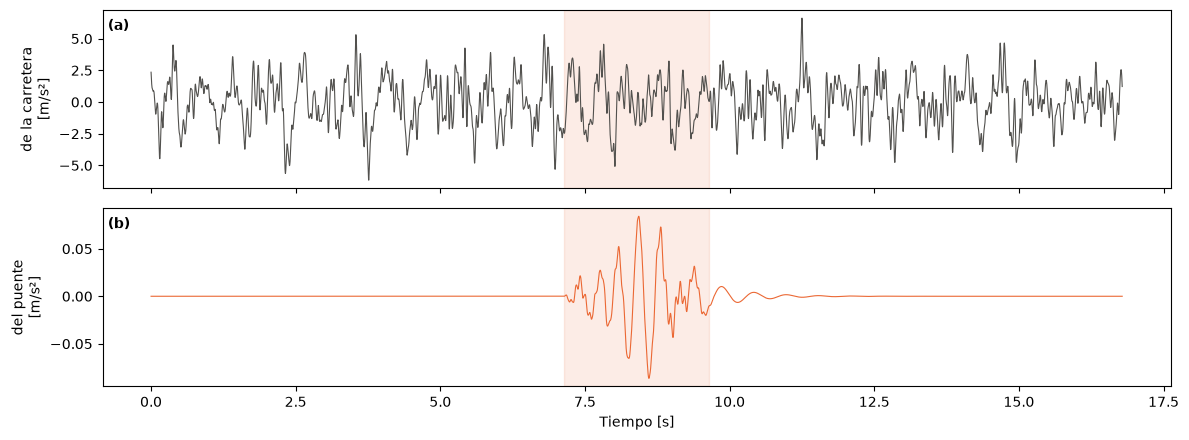

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
ax1.plot(t[keep], acc_road[keep], color="#52514e", lw=0.8)
ax1.set_ylabel("de la carretera\n[m/s²]")
ax2.plot(t[keep], acc_bridge[keep], color="#eb6834", lw=0.8)
ax2.set_ylabel("del puente\n[m/s²]")
ax2.set_xlabel("Tiempo [s]")
for ax, letter in zip((ax1, ax2), "ab"):
    ax.axvspan(t[on_bridge][0], t[on_bridge][-1], color="#eb6834", alpha=0.12)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 6.** Aceleración de la carrocería separada por fuente (Ec. 11). (a) Parte que viene de la carretera. (b) Parte que viene del puente (suma de sus modos). Cada panel tiene su propia escala.

- La parte del puente es una oscilación suave de unos 3 Hz: el carro deja pasar el modo 1 y frena los modos 2 y 3.
- Después de salir del puente, la parte del puente se apaga poco a poco: es el carro que sigue oscilando un momento.

## 7. El teléfono

El teléfono no guarda la aceleración tal cual. Hace tres cosas:

1. **Filtro anti-alias:** un filtro pasa-bajos (Butterworth de orden 4, corte en 80 Hz = 0.4 × 200 Hz) quita lo que el teléfono no puede registrar a 200 muestras por segundo.
2. **Muestreo a 200 Hz:** de cada 5 muestras de la simulación (1000 Hz) se guarda 1.
3. **Ruido blanco:** el sensor agrega un ruido aleatorio con desviación estándar

$$\sigma = ND \cdot g \cdot \sqrt{f_s / 2} \tag{12}$$

- $ND$: densidad de ruido del sensor (312 µg/√Hz = 312·10⁻⁶ g/√Hz).
- $g$ = 9.81 m/s²; $f_s$ = 200 Hz: muestras por segundo del teléfono.

Los pasos 1 y 2 se aplican igual a cada componente. El ruido se suma solo una vez. Así se cumple:

$$\text{measured} = \text{carretera} + \text{puente (modo 1 + modo 2 + ...)} + \text{ruido}$$

In [12]:
sos = signal.butter(4, 0.4 * FS_OUT, btype="low", fs=FS_SIM, output="sos")   # anti-alias filter


def phone(acc):
    """Anti-alias filter, keep the saved window and one of every 5 samples (1000 -> 200 Hz)."""
    filtered = signal.sosfiltfilt(sos, acc)
    return filtered[keep][:: FS_SIM // FS_OUT]


road_part = phone(acc_road)
bridge_part = phone(acc_bridge)
sigma = noise_density * 1e-6 * 9.81 * np.sqrt(FS_OUT / 2)   # Eq. 12
noise = sigma * rng.standard_normal(len(road_part))
measured = road_part + bridge_part + noise

t_out = np.arange(len(measured)) / FS_OUT
on_out = on_bridge[keep][:: FS_SIM // FS_OUT]
print(f"Phone signal: {len(measured)} samples ({len(measured) / FS_OUT:.1f} s)")
print(f"RMS on the bridge: road {road_part[on_out].std():.3f}, bridge {bridge_part[on_out].std():.3f}, "
      f"noise {noise[on_out].std():.3f} m/s^2")

Phone signal: 3357 samples (16.8 s)
RMS on the bridge: road 1.852, bridge 0.033, noise 0.029 m/s^2


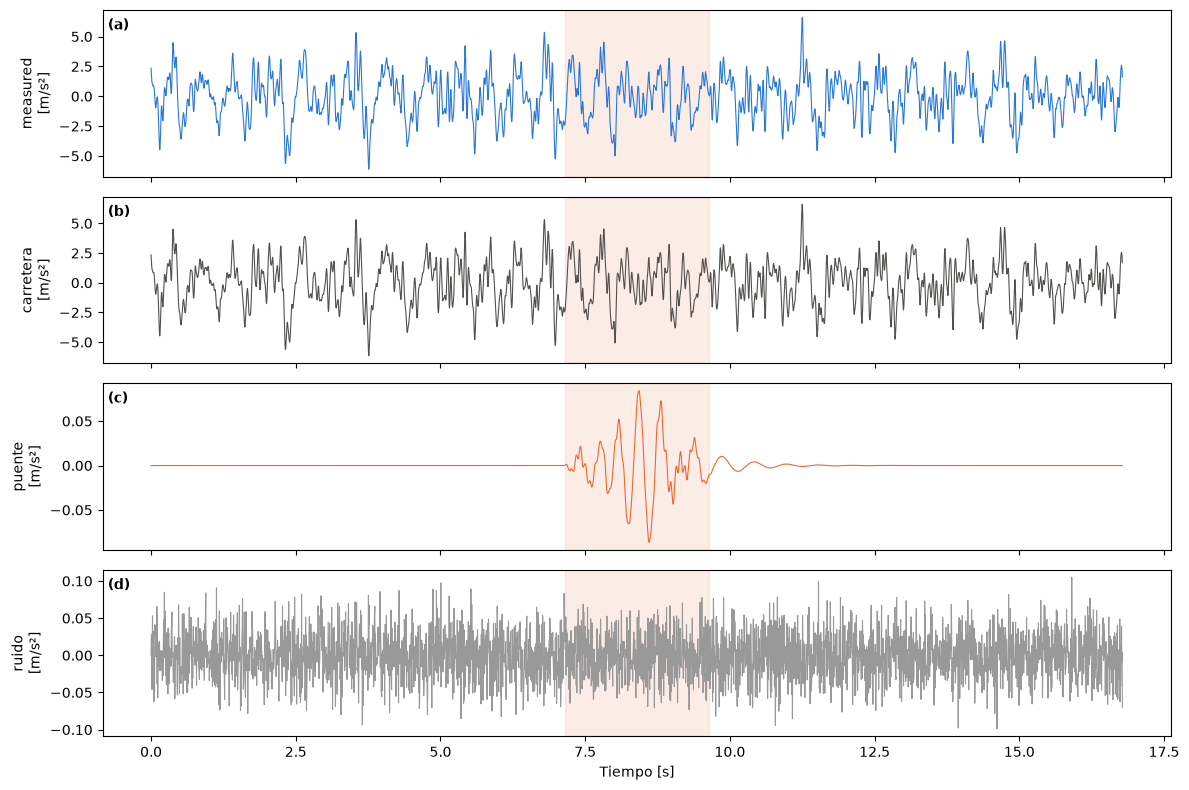

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
parts = [(measured, "measured", "#2a78d6"), (road_part, "carretera", "#52514e"),
         (bridge_part, "puente", "#eb6834"), (noise, "ruido", "0.6")]
for ax, (sig, name, color), letter in zip(axes, parts, "abcd"):
    ax.plot(t_out, sig, color=color, lw=0.8)
    ax.axvspan(t_out[on_out][0], t_out[on_out][-1], color="#eb6834", alpha=0.12)
    ax.set_ylabel(f"{name}\n[m/s²]")
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 7.** Señal final del teléfono y sus partes. (a) Lo que mide el teléfono (`measured`). (b) Parte de la carretera. (c) Parte del puente. (d) Ruido del sensor. (a) = (b) + (c) + (d). Cada panel tiene su propia escala.

- La señal medida es casi igual a la parte de la carretera. Sobre el puente, la parte del puente y el ruido son de tamaño parecido, y los dos son unas 60 veces más pequeños que la carretera (RMS).
- El puente solo está en la señal durante unos 2.5 s (y un poco después, mientras el carro deja de oscilar).

## 8. Resumen

1. **Puente:** cada modo es un oscilador empujado por ruido blanco (el tráfico) (Ec. 3).
2. **Carretera:** un perfil aleatorio con el espectro de su clase ISO 8608, armado como suma de ondas (Ec. 4–5).
3. **Rueda:** pisa la carretera más el movimiento del puente en el punto donde está (Ec. 7).
4. **Carro:** el cuarto de carro filtra esa entrada (Ec. 8–10). Deja pasar las frecuencias bajas, como el modo 1, y frena las altas.
5. **Separación:** cada fuente se pasa por el carro por separado; la suma es la señal total (Ec. 11).
6. **Teléfono:** filtro anti-alias, 200 muestras por segundo y ruido blanco (Ec. 12).

**Tabla 2.** Dónde está cada cantidad del notebook en los archivos del dataset.

| En este notebook | En el archivo `.h5` |
|---|---|
| `measured` | `measured` |
| `road_part` | `components/roughness` |
| parte del modo n de `bridge_part` | `components/bridge_mode_n` (los modos 4 en adelante en `bridge_higher_modes`) |
| `noise` | `components/noise` |
| $r(x(t))$ | `profile/road_displacement` |
| $v^2\, r''(x)$ (aceleración que la carretera impone a la rueda) | `profile/road_acceleration` (`road_acc`) |
| $\sum \phi_n q_n$ | `profile/bridge_displacement` |
| $\sum \phi_n \ddot q_n$ (aceleración del puente bajo la rueda) | `profile/bridge_acceleration` (`bridge_acc`) |

Lo que el simulador hace distinto, sin cambiar la idea:

- No usa calentamiento: arranca el puente y el carro directamente en su estado de vibración estable.
- Calcula la fuerza del tráfico para que la amplitud salga directamente, en vez de escalar después.
- Calcula la rugosidad y sus derivadas con fórmulas exactas (más rápido que el ciclo de la sección 3).